#### Importing necessary libraries

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### list of files in dbfs

In [0]:
%fs ls dbfs:///FileStore/tables/

path,name,size,modificationTime
dbfs:/FileStore/tables/Customers__1_-1.csv,Customers__1_-1.csv,1043,1710705699000
dbfs:/FileStore/tables/Customers__1_.csv,Customers__1_.csv,1043,1710705669000
dbfs:/FileStore/tables/Drugs_package.csv,Drugs_package.csv,27234691,1707889380000
dbfs:/FileStore/tables/Drugs_product.csv,Drugs_product.csv,38743242,1707889380000
dbfs:/FileStore/tables/EmployeeSale__1_.csv,EmployeeSale__1_.csv,2736,1710705733000
dbfs:/FileStore/tables/Employee__1_.csv,Employee__1_.csv,385,1710705688000
dbfs:/FileStore/tables/Gender_crosswalk.txt,Gender_crosswalk.txt,72,1709286187000
dbfs:/FileStore/tables/Products__1_.csv,Products__1_.csv,367,1710705650000
dbfs:/FileStore/tables/Relationship_crosswalk.txt,Relationship_crosswalk.txt,264,1709286188000
dbfs:/FileStore/tables/Sales__1_.csv,Sales__1_.csv,2714,1710705719000


####Load data from CSV files into Spark DataFrames and display them.

In [0]:
yellow_taxi = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .load("dbfs:/FileStore/tables/yellow_taxi2.csv")

In [0]:
display(yellow_taxi)

VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge
1,7/1/2021 0:30,7/1/2021 0:35,N,1,74,168,1,1.2,6.0,0.5,0.5,0.0,0.0,null,0.3,7.3,2,1,0.0
2,7/1/2021 0:25,7/1/2021 1:01,N,1,116,265,2,13.69,42.0,0.5,0.5,0.0,0.0,null,0.3,43.3,2,1,0.0
2,7/1/2021 0:05,7/1/2021 0:12,N,1,97,33,1,0.95,6.5,0.5,0.5,2.34,0.0,null,0.3,10.14,1,1,0.0
2,7/1/2021 0:41,7/1/2021 0:47,N,1,74,42,1,1.24,6.5,0.5,0.5,0.0,0.0,null,0.3,7.8,2,1,0.0
2,7/1/2021 0:51,7/1/2021 0:58,N,1,42,244,1,1.1,7.0,0.5,0.5,0.0,0.0,null,0.3,8.3,2,1,0.0
1,7/1/2021 0:05,7/1/2021 0:11,N,1,24,239,1,1.9,8.0,3.25,0.5,3.0,0.0,null,0.3,15.05,1,1,2.75
2,7/1/2021 0:57,7/1/2021 1:27,N,1,75,243,1,0.0,17.5,0.5,0.5,0.0,0.0,null,0.3,18.8,2,1,0.0
2,7/1/2021 0:27,7/1/2021 0:32,N,1,82,82,1,0.66,5.0,0.5,0.5,0.0,0.0,null,0.3,6.3,2,1,0.0
2,7/1/2021 0:29,7/1/2021 0:34,N,1,74,42,1,1.72,7.0,0.5,0.5,2.08,0.0,null,0.3,10.38,1,1,0.0
2,7/1/2021 0:41,7/1/2021 0:49,N,1,41,42,1,1.37,7.5,0.5,0.5,0.0,0.0,null,0.3,8.8,2,1,0.0


####Convert Spark DataFrames to pandas DataFrames for further processing.

In [0]:
yellow_taxi_df = yellow_taxi.toPandas()

In [0]:
yellow_taxi_df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge
0,1.0,7/1/2021 0:30,7/1/2021 0:35,N,1.0,74,168,1.0,1.20,6.00,0.50,0.5,0.00,0.00,None,0.3,7.30,2.0,1.0,0.0
1,2.0,7/1/2021 0:25,7/1/2021 1:01,N,1.0,116,265,2.0,13.69,42.00,0.50,0.5,0.00,0.00,None,0.3,43.30,2.0,1.0,0.0
2,2.0,7/1/2021 0:05,7/1/2021 0:12,N,1.0,97,33,1.0,0.95,6.50,0.50,0.5,2.34,0.00,None,0.3,10.14,1.0,1.0,0.0
3,2.0,7/1/2021 0:41,7/1/2021 0:47,N,1.0,74,42,1.0,1.24,6.50,0.50,0.5,0.00,0.00,None,0.3,7.80,2.0,1.0,0.0
4,2.0,7/1/2021 0:51,7/1/2021 0:58,N,1.0,42,244,1.0,1.10,7.00,0.50,0.5,0.00,0.00,None,0.3,8.30,2.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83686,NaN,7/2/2021 7:59,7/2/2021 8:33,None,NaN,218,169,NaN,18.04,50.24,2.75,0.0,0.00,6.55,None,0.3,59.84,NaN,NaN,NaN
83687,NaN,7/2/2021 7:02,7/2/2021 7:18,None,NaN,74,137,NaN,5.56,19.16,0.00,0.0,3.66,0.00,None,0.3,25.87,NaN,NaN,NaN
83688,NaN,7/2/2021 7:53,7/2/2021 8:15,None,NaN,69,75,NaN,5.13,22.45,0.00,0.0,0.00,0.00,None,0.3,22.75,NaN,NaN,NaN
83689,NaN,7/2/2021 7:58,7/2/2021 8:30,None,NaN,117,82,NaN,12.58,48.62,2.75,0.0,0.00,2.45,None,0.3,54.12,NaN,NaN,NaN


####1.	Determine the maximum fare amount for trips where the pickup location is the same as the drop-off location, excluding trips with zero fare

In [0]:
##2.	Identify the top 5 vendors based on the total fare amount collected, considering only trips with a positive fare amount##2.	Identify the top 5 vendors based on the total fare amount collected, considering only trips with a positive fare amount
from pyspark.sql.functions import col, max ,sum
df2 = yellow_taxi.filter(col("PULocationID")== col("DOLocationID"))
df2 = df2.filter(col("fare_amount") != 0)
#df2.display()
max_fare =df2.agg({"fare_amount": "max"}).collect()[0][0]
max_fare

Out[6]: 480.0

####2.	Identify the top 5 PULocationID based on the total fare amount collected, considering only trips with a positive fare amount

In [0]:
from pyspark.sql.functions import sum,round
total_fare_amount =yellow_taxi \
    .filter((col("fare_amount") > 0) & col("PULocationID").isNotNull()) \
    .groupBy("PULocationID") \
    .agg(round(sum("fare_amount"), 2).alias("total_fare_amount")) \
    .orderBy("total_fare_amount", ascending=False) \
    .limit(5)
total_fare_amount.show()

+------------+-----------------+
|PULocationID|total_fare_amount|
+------------+-----------------+
|          74|        106005.74|
|          75|         97653.91|
|          41|          59273.0|
|          42|         46898.26|
|         244|         44872.62|
+------------+-----------------+



### Visualization Task : Visualize the relationship between trip distance and tip amount, colored by payment type.

##### steps
•	Filter out trips with positive tip amount.

•	Extract trip distance and tip amount.

•	Plot a scatter plot of trip distance vs. tip amount, coloring points by payment type


In [0]:
yellow_taxi_df.describe()

,VendorID,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge
count,51173.000000,51173.000000,83691.000000,83691.000000,51173.000000,83691.000000,83691.000000,83691.000000,83691.000000,83691.000000,83691.000000,83691.000000,83691.000000,51173.000000,51173.000000,51173.000000
mean,1.851113,1.159244,108.362572,133.270005,1.307858,194.354699,20.388305,1.156707,0.293562,1.058618,0.624529,0.297745,24.204836,1.421726,1.034393,0.642815
std,0.355981,0.773260,70.370170,77.216791,0.984362,4405.549221,15.583552,1.367897,0.247773,2.368771,1.990481,0.031219,17.262183,0.511146,0.182239,1.164219
min,1.000000,1.000000,3.000000,1.000000,0.000000,0.000000,-150.000000,-4.500000,-0.500000,-1.140000,0.000000,-0.300000,-150.300000,1.000000,1.000000,-2.750000
25%,2.000000,1.000000,56.000000,69.000000,1.000000,1.350000,9.000000,0.000000,0.000000,0.000000,0.000000,0.300000,11.760000,1.000000,1.000000,0.000000
50%,2.000000,1.000000,75.000000,132.000000,1.000000,2.760000,16.000000,0.500000,0.500000,0.000000,0.000000,0.300000,19.800000,1.000000,1.000000,0.000000
75%,2.000000,1.000000,166.000000,205.000000,1.000000,6.200000,26.830000,2.750000,0.500000,1.660000,0.000000,0.300000,31.300000,2.000000,1.000000,0.000000
max,2.000000,5.000000,265.000000,265.000000,32.000000,260517.930000,480.000000,8.250000,0.500000,87.710000,30.050000,0.300000,480.310000,5.000000,2.000000,2.750000


In [0]:
yellow_taxi_df.dtypes

Out[9]: VendorID                 float64
lpep_pickup_datetime      object
lpep_dropoff_datetime     object
store_and_fwd_flag        object
RatecodeID               float64
PULocationID               int32
DOLocationID               int32
passenger_count          float64
trip_distance            float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
ehail_fee                 object
improvement_surcharge    float64
total_amount             float64
payment_type             float64
trip_type                float64
congestion_surcharge     float64
dtype: object

##A correlation coefficient of approximately -0.011 between the trip_distance and tip_amount columns suggests a very weak, almost negligible linear relationship between these two variables

#### on whole data

In [0]:
correlation =yellow_taxi_df['tip_amount'].corr(yellow_taxi_df['trip_distance'])
correlation

Out[13]: -0.01101323475667395

#### on filterd data after applying condition tip_amount >= 0

In [0]:
positive_tip_df = yellow_taxi_df[yellow_taxi_df['tip_amount'] >= 0]
correlation1 =positive_tip_df['tip_amount'].corr(positive_tip_df['trip_distance'])
correlation1

Out[21]: -0.011020469709565819

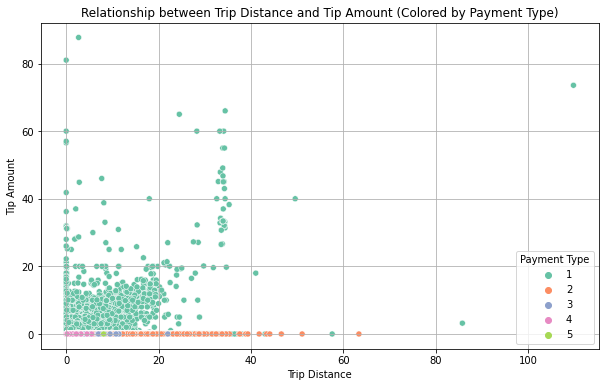

In [0]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd



# Filter out trips with positive tip amount
positive_tip_df = yellow_taxi_df[yellow_taxi_df['tip_amount'] >= 0]

# Extract trip distance, tip amount, and payment type
trip_distance = positive_tip_df['trip_distance']
tip_amount = positive_tip_df['tip_amount']
payment_type = positive_tip_df['payment_type']

# Create a DataFrame with all payment types
all_payment_types_df = pd.DataFrame({'payment_type': [1, 2,3,4,5]})
# Merge it with your original DataFrame to ensure all payment types are present
merged_df = all_payment_types_df.merge(positive_tip_df, on='payment_type', how='left')

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=merged_df, x='trip_distance', y='tip_amount', hue='payment_type', palette='Set2')

# Set plot labels and title
plt.title("Relationship between Trip Distance and Tip Amount (Colored by Payment Type)")
plt.xlabel("Trip Distance")
plt.ylabel("Tip Amount")
plt.legend(title="Payment Type")
plt.grid(True)
plt.show()


##the correlation coefficient between  variables trip_distance and tip_amount is  -0.01101  suggests a very weak, almost negligible linear relationship between these two variables. 

#Conclusion :  
###Since the correlation is close to zero, there's no clear trend or pattern in the relationship between these two variables. This suggests that the distance of the trip  does not have a strong influence on the amount of tip given 

##This means that knowing the value of one variable (trip_distance) does not provide much information about the value of the other variable(tip_amount) in a linear sense.